# Session 3: exploratory data analysis of your dataset

Session 2 focused on finding and loading one media file. This session moves outward: a metadata table describes a collection of samples and helps you see how that collection is organized.

Part 1 is a short worked camera-trap example. **Part 2, using your own metadata, is the main activity.** If your metadata are not ready, use the example table in Part 2 and record what you need before January.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Part 1: worked camera-trap example

The supplied table is fictional, but its columns resemble common camera-trap and iWildCam metadata: an ID and filename for each record, a category, a location, a deployment or sequence-like group, a timestamp, and annotation status. It is small enough to inspect directly.

In [2]:
possible_example_paths = [
    Path.cwd() / "example_metadata.csv",
    Path.cwd() / "03_understand_your_data" / "example_metadata.csv",
    Path.cwd() / "Deliverables" / "prep" / "03_understand_your_data" / "example_metadata.csv",
]
example_path = next((path for path in possible_example_paths if path.exists()), None)
if example_path is None:
    raise FileNotFoundError(f"Could not find example_metadata.csv from {Path.cwd()}")

example = pd.read_csv(example_path)
print("Rows and columns:", example.shape)
display(example.head())

Rows and columns: (24, 8)


,sample_id,filename,species,site,deployment,timestamp,annotation_status,quality_note
0,S001,site_a_001.jpg,deer,north,N1,2026-05-01 05:12,labeled,NaN
1,S002,site_a_002.jpg,deer,north,N1,2026-05-01 05:13,labeled,NaN
2,S003,site_a_003.jpg,empty,north,N1,2026-05-01 06:45,labeled,NaN
3,S004,site_a_004.jpg,fox,north,N2,2026-05-03 21:10,labeled,NaN
4,S005,site_a_005.jpg,fox,north,N2,2026-05-03 21:11,labeled,blurred


## Read the structure before calculating summaries

In this table, one row represents one image record. `sample_id` identifies the record and `filename` points toward its media. Other columns describe that record or connect it to a larger group.

The next cells answer three basic EDA questions:

1. What information is available?
2. What important information is missing?
3. How are records distributed across a target and a natural group?

In [3]:
print("Columns:", example.columns.tolist())
print("\nData types:")
display(example.dtypes.to_frame("dtype"))
print("Missing values:")
display(example.isna().sum().to_frame("missing_rows"))

Columns: ['sample_id', 'filename', 'species', 'site', 'deployment', 'timestamp', 'annotation_status', 'quality_note']

Data types:


,dtype
sample_id,str
filename,str
species,str
site,str
deployment,str
timestamp,str
annotation_status,str
quality_note,str


Missing values:


,missing_rows
sample_id,0
filename,0
species,4
site,0
deployment,0
timestamp,0
annotation_status,0
quality_note,19


In [4]:
species_counts = example["species"].fillna("<missing>").value_counts()
site_counts = example["site"].fillna("<missing>").value_counts()
species_by_site = pd.crosstab(
    example["site"],
    example["species"].fillna("<missing>"),
)
print("Species counts:")
display(species_counts.to_frame("records"))
print("Species by site:")
display(species_by_site)

Species counts:


,records
species,
deer,6
empty,5
<missing>,4
fox,3
raccoon,3
bear,3


Species by site:


species,<missing>,bear,deer,empty,fox,raccoon
site,,,,,,
east,1,3,0,1,0,1
north,1,0,2,1,2,0
south,1,0,2,2,0,1
west,1,0,2,1,1,1


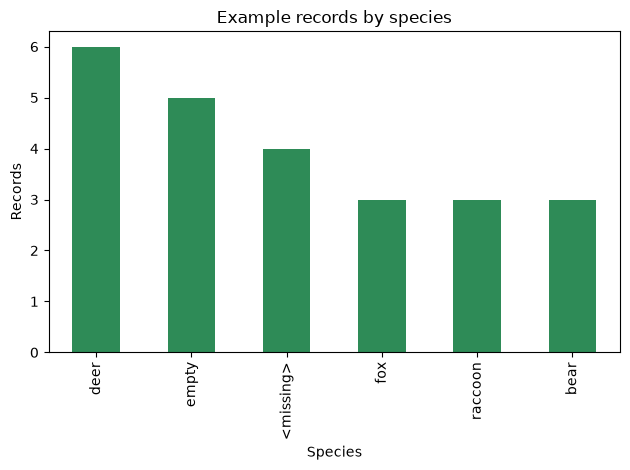

In [5]:
ax = species_counts.plot(kind="bar", color="seagreen")
ax.set(title="Example records by species", xlabel="Species", ylabel="Records")
plt.tight_layout()
plt.show()

A useful EDA observation names evidence rather than merely saying a graph is interesting. For example: **four records lack a species label, with one unlabeled record at each site.** A useful follow-up question is: **does `annotation_status` explain those missing labels?**

# Part 2: explore your own metadata

Set `MY_DATA_PATH` to a small CSV extract from your project. Keep research data outside this repository. If your metadata are not ready, leave it as `None`; the notebook will use the example so you can still practice the workflow.

In [11]:
MY_DATA_PATH = Path("C:/Users/lilia/OneDrive - The University of Montana/workshops/cv/Example_data/Example_ImageData5.csv")

if MY_DATA_PATH is None:
    metadata = example.copy()
    using_example = True
    print("Using the supplied example. Replace MY_DATA_PATH when your metadata are ready.")
else:
    metadata = pd.read_csv(Path(MY_DATA_PATH).expanduser())
    using_example = False
    print("Using your metadata:", Path(MY_DATA_PATH).expanduser())

Using your metadata: C:\Users\lilia\OneDrive - The University of Montana\workshops\cv\Example_data\Example_ImageData5.csv


## 1. Define what the table represents

Do not begin with calculations. First determine what the table means.

- **One row represents:** One image
- **The table covers:** 5 example images
- **It was created by or exported from:** Exported from Timelapse image processing software
- **Important information stored elsewhere:** Camera location, megadetector info, other metadata

## 2. Inspect shape, columns, and types

Run this cell, then inspect several rows in the CSV itself. Do not assume Pandas interpreted every column correctly—dates and identifiers often need special attention.

In [12]:
print("Rows and columns:", metadata.shape)
print("Columns:", metadata.columns.tolist())
display(metadata.head())
display(metadata.dtypes.to_frame("dtype"))

Rows and columns: (6, 35)
Columns: ['File', 'DateTime', 'clear_view', 'species_name', 'band_count', 'mcount_first', 'fcount_first', 'usex_count_first', 'jcount_first', 'uage_count_first', 'mcount_second', 'fcount_second', 'usex_count_second', 'jcount_second', 'uage_count_second', 'mcount_third', 'fcount_third', 'usex_count_third', 'jcount_third', 'uage_count_third', 'tagged_animal', 'trigger_mode', 'flash', 'notes', 'mcount_first_or_second', 'fcount_first_or_second', 'usex_count_first_or_second', 'jcount_first_or_second', 'uage_count_first_or_second', 'mcount_second_or_third', 'fcount_second_or_third', 'usex_count_second_or_third', 'jcount_second_or_third', 'uage_count_second_or_third', 'color_scale']


,File,DateTime,clear_view,species_name,band_count,mcount_first,fcount_first,usex_count_first,jcount_first,uage_count_first,...,fcount_first_or_second,usex_count_first_or_second,jcount_first_or_second,uage_count_first_or_second,mcount_second_or_third,fcount_second_or_third,usex_count_second_or_third,jcount_second_or_third,uage_count_second_or_third,color_scale
0,Site-0232_MFWP0229_02580.JPG,2024-07-10 05:10:00,1,MD,All,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
1,Site-0351_MFWP0452_04596.JPG,2024-07-15 04:10:00,1,DeerSpp,NaN,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,Site-0130_MFWP0190_11974.JPG,2024-07-28 00:00:00,0,NoAnimal,NaN,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Site-0213_MFWP0331_09386.JPG,2024-08-10 07:50:00,1,WTD,All,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,1
4,Site-0323_MFWP0393_13787.JPG,2024-09-30 02:40:00,1,ELK,NaN,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


,dtype
File,str
DateTime,str
clear_view,int64
species_name,str
band_count,str
mcount_first,int64
fcount_first,int64
usex_count_first,int64
jcount_first,int64
uage_count_first,int64


- **A column whose type needs checking:** looks good
- **Why:** _Write here._

## 3. Name the columns that organize your data

Edit these settings to match your table. A natural group contains related observations that should not be treated as completely independent—for example a site, deployment, sequence, individual, video, recorder, or sampling event. Use `None` if your table truly has no corresponding column.

In [15]:
ID_COLUMN = "File"
MEDIA_COLUMN = "File"
TARGET_COLUMN = "species_name"
GROUP_COLUMN = None

selected_columns = {
    "ID_COLUMN": ID_COLUMN,
    "MEDIA_COLUMN": MEDIA_COLUMN,
    "TARGET_COLUMN": TARGET_COLUMN,
    "GROUP_COLUMN": GROUP_COLUMN,
}
for role, column in selected_columns.items():
    if column is not None and column not in metadata.columns:
        raise KeyError(f"{role} is set to {column!r}, but that column is not in the table")
display(pd.DataFrame([selected_columns]))

,ID_COLUMN,MEDIA_COLUMN,TARGET_COLUMN,GROUP_COLUMN
0,File,File,species_name,None


- **Why is this the appropriate ID column?** Right now, using the file name as an individual ID. I am not sure how a ID column would be different from this. If the table should reflect every animal detection instead of every image, I could expand the table and use a unique ID for each animal detection
- **What does the natural group represent?** A group would be each site. I do not have a seperate site coumn right now, but can easily add that from the file name. 
- **If a needed role is missing, where is that information stored?** Group column can be made from the file name. Not sure what I should use for id_column

## 4. Check missing values and identifiers

Missing values are not automatically errors. Identify where they occur before deciding what they mean. IDs require a separate check: duplicated IDs may be expected if one sample occupies several rows, or may reveal a problem if every row should be unique.

In [16]:
missing_summary = metadata.isna().sum().sort_values(ascending=False)
display(missing_summary.to_frame("missing_rows"))

if ID_COLUMN is not None:
    print("Rows:", len(metadata))
    print("Unique non-missing IDs:", metadata[ID_COLUMN].nunique())
    print("Rows with duplicated IDs:", metadata[ID_COLUMN].duplicated(keep=False).sum())

,missing_rows
notes,6
tagged_animal,6
band_count,3
clear_view,0
DateTime,0
File,0
species_name,0
usex_count_first,0
jcount_first,0
mcount_first,0


Rows: 6
Unique non-missing IDs: 6
Rows with duplicated IDs: 0


- **Most consequential missing value:** Notes and tagged_animal are usually blank, which is fine. band_count should never be blank, i think the code intepreted a value of "none" as blank. This is not consequential because this field is not important. 
- **Are repeated IDs expected for what one row represents?** IDs should not be duplicated because each row is an image.

## 5. Count a target and a natural group

The helper below includes missing values explicitly. Run it for the target and group you selected. If either setting is `None`, explain what alternative summary would be meaningful for your project.

In [17]:
def counts_including_missing(table, column):
    if column is None:
        return None
    return table[column].fillna("<missing>").value_counts()

target_counts = counts_including_missing(metadata, TARGET_COLUMN)
group_counts = counts_including_missing(metadata, GROUP_COLUMN)
if target_counts is not None:
    print("Target counts:")
    display(target_counts.to_frame("rows"))
if group_counts is not None:
    print("Group counts:")
    display(group_counts.to_frame("rows"))

Target counts:


,rows
species_name,
MD,2
DeerSpp,1
NoAnimal,1
WTD,1
ELK,1


- **A notable target count:** Count represents one image of that animal
- **A notable group count:** Would represent how many images from a site
- **What these counts do not tell you:** Counts show number of images, not number of individuals

## 6. Compare the target across groups

A total count can hide differences among sites, deployments, sequences, or other groups. If you selected both columns, the crosstab below makes that relationship visible.

In [18]:
if TARGET_COLUMN is not None and GROUP_COLUMN is not None:
    target_by_group = pd.crosstab(
        metadata[GROUP_COLUMN].fillna("<missing>"),
        metadata[TARGET_COLUMN].fillna("<missing>"),
    )
    display(target_by_group)
else:
    print("Choose both TARGET_COLUMN and GROUP_COLUMN to make this comparison.")

Choose both TARGET_COLUMN and GROUP_COLUMN to make this comparison.


- **One relationship visible here but hidden in the totals:** could show images per site, autocorrelation

## 7. Make one useful plot

Choose whether the target or group counts better address a question about your data. Assign that Series and a clear title below. Avoid plotting an identifier column: a separate bar for every sample rarely helps.

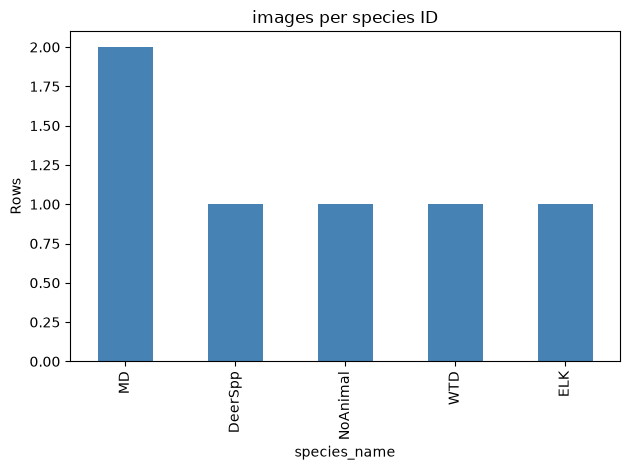

In [20]:
counts_to_plot = target_counts  # Change to group_counts if that is more useful.
plot_title = f"images per species ID"  # Edit to describe your plot.

if counts_to_plot is None:
    raise ValueError("Choose a column and create counts before plotting")
ax = counts_to_plot.plot(kind="bar", color="steelblue")
ax.set(title=plot_title, xlabel=counts_to_plot.index.name, ylabel="Rows")
plt.tight_layout()
plt.show()

- **What the plot shows:** One row per image
- **Question it raises:** Shows rows be images or individual detections

## 8. Check links from metadata to media when possible

This connects session 3 back to the file work in session 2 and forward to the dataset object in session 4. If you have a small local media directory and a filename column, set `MY_MEDIA_DIR`. Otherwise leave it as `None` and describe how media paths are recorded in your project.

In [22]:
MY_MEDIA_DIR = Path("C:/Users/lilia/OneDrive - The University of Montana/workshops/cv/Example_data")

if MY_MEDIA_DIR is not None and MEDIA_COLUMN is not None:
    media_dir = Path(MY_MEDIA_DIR).expanduser()
    expected_paths = metadata[MEDIA_COLUMN].dropna().map(lambda name: media_dir / str(name))
    missing_media = expected_paths[~expected_paths.map(Path.exists)]
    print("Media paths checked:", len(expected_paths))
    print("Files not found:", len(missing_media))
    display(missing_media.head().to_frame("missing_path"))
else:
    print("Media check skipped. Record below how table rows connect to media.")

Media paths checked: 6
Files not found: 0


,missing_path


- **How a row connects to its media:** each row is an image
- **How a row connects to annotations, if separate:** unsure
- **Any mismatches or information still needed:** 

## 9. Inspect a focused view of the table

Filtering is useful during EDA when a summary raises a question. Write one Boolean condition that selects rows you want to inspect—for example missing labels, one site, one annotation status, or records with a quality note. This is an exploratory view, **not** your final development or model-training subset.

In [26]:
# Replace this condition with one that addresses your EDA question.
if TARGET_COLUMN is not None:
    condition = metadata["clear_view"] == 0
else:
    condition = pd.Series(True, index=metadata.index)
focused_view = metadata.loc[condition].copy()
print("Selected rows:", len(focused_view))
display(focused_view.head(10))

Selected rows: 1


,File,DateTime,clear_view,species_name,band_count,mcount_first,fcount_first,usex_count_first,jcount_first,uage_count_first,...,fcount_first_or_second,usex_count_first_or_second,jcount_first_or_second,uage_count_first_or_second,mcount_second_or_third,fcount_second_or_third,usex_count_second_or_third,jcount_second_or_third,uage_count_second_or_third,color_scale
2,Site-0130_MFWP0190_11974.JPG,2024-07-28 00:00:00,0,NoAnimal,NaN,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


- **Why I selected these rows:** TO examine rows with obstructed views
- **What I learned by inspecting them:** Should obstructed images be removed from the dataset? Should blank images be removed?

# EDA notes to bring to the instructors

Complete these in plain language. The goal is not a polished report.

- **I used my own metadata / the supplied fallback:** my own
- **Approximate scope represented by this table:** 5 images
- **One row represents:** one image
- **Sample ID and media connection:** Each ID is a file name, same as the media
- **Most important missing or questionable information:** add a site column, total_count column
- **Most useful count or plot:** count per species
- **One concrete question for the instructors:** Should each row be one image or one animal detection? How should an ID be different from a filename?
- **If I used the fallback, what is needed to explore my data:** NA

## Connection to the next sessions

In session 4, you will use IDs and paths to load the files belonging to one complete sample through a dataset class. In session 6, you and the instructors will use observations from this EDA to plan a manageable working subset. Formal train/validation/test splitting remains course content.